# Where a coding AI picks its algorithm: fork margin vs. default-to-runner-up axis (Qwen3-8B)

**Demo of `method.py` from artifact `art_pHL7LWNhpcCS` (iteration 7, experiment 34).**

Asked to solve a memorised coding task, bf16 **Qwen3-8B** (revision `b968826d`, thinking off, T = 1) almost always
writes its *default* algorithm: union-find for **T10** (connected components) and Dijkstra for **T2** (weighted
shortest path). Pushing the prompt's hidden states along a random direction (alpha 2, blocks 12-23, task-spec
positions, prefill only) sometimes makes it write a *different, correct* algorithm instead. The share of such programs
is the push's outcome **y**. The experiment asks what decides **which** of 40 equal-dose random pushes escape the
default:

* **F: fork margin.** Prefix resampling (4,560 continuations) first locates the *forks*, the generated tokens where
  the algorithm is decided. On T10 these are tokens 10 and 11, the first words of the function body after
  `def solve(n, edges):`. There `' parent'` leads to union-find, `' #'` or `' from'` to graph search, and `' def'`
  continues as `' find'` (union-find) or `' dfs'` (DFS). The **fork margin m** is the logit of the probability mass a
  pushed prompt puts on the off-default fork tokens (teacher-forced, no sampling). T2 has no early fork, so its margin
  is the pre-declared fallback, a 48-token opening log-likelihood ratio.
* **P2: axis.** The competing hypothesis says a *default-to-runner-up axis* in the prompt states mediates the pushes.
  The axis is the difference in means between prompts that force the runner-up algorithm and their padding twins. The
  predictor is the push's projection **b** on that axis, compared with three baselines: the P_t subspace energy share,
  the raw displacement norm and the U4 energy share.

Both hypotheses and their thresholds were hash-committed (sha256 chain, commit #0) before any outcome row was opened.

**What this notebook runs.** `method.py` is an orchestrator. It runs 8 stages, each a separate script under `src/`,
and most stages need a 24 GB GPU and the 16 GB model. This notebook re-runs, on CPU in about a minute, the two steps
that turn the saved GPU measurements into the committed verdicts:

1. the CPU half of stage `predict` (`src/predict7.py`): the fork-margin rule, applied to the saved teacher-forced
   fork-token probabilities of all 40 pushed T10 prompts;
2. stage `analysis` (`src/analysis7.py` with `src/stats7.py`; figures from `src/figures7.py`): Spearman tests with
   permutation p values, bootstrap CIs and tie ceilings, a paired bootstrap of P2 against its three baselines, a
   binomial-GLM calibration, and the pre-registered verdict rules with Holm correction.

**Data.** `mini_demo_data.json` is the `p2_directions` dataset of `method_out.json`: all 80 pushed cells (40 random
directions × T10, T2). Each cell carries its committed predictors (commit #3b) and its outcome counts, so every
recomputed number can be checked against the paper.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py (the orchestrator), its import block as-is; argparse/subprocess drive the GPU stages of the full repository
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/analysis7.py, src/stats7.py, src/predict7.py, src/figures7.py (the steps this notebook runs)
import json
import math
from collections import defaultdict
from typing import Any, Sequence

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/experiment-34/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

examples = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(examples)} pushed cells "
      f"({sum(e['metadata_task'] == 'T10' for e in examples)} T10, {sum(e['metadata_task'] == 'T2' for e in examples)} T2)")
print("model:", data["metadata"]["model"])
# one row per pushed cell: committed fork margin m, axis projection b, outcome y and the algorithms written
pd.DataFrame([{"cell": e["metadata_cell_key"], "m": e["metadata_committed_predictors"]["m"],
               "b": e["metadata_committed_predictors"]["b"], "y": e["metadata_outcome"]["y"],
               "N": e["metadata_outcome"]["n"], "labels": e["metadata_outcome"]["labels"]} for e in examples]).head()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'p2_directions': 80 pushed cells (40 T10, 40 T2)
model: Qwen/Qwen3-8B b968826d9c46dd6066d109eabc6255188de91218, bf16, thinking off


,cell,m,b,y,N,labels
0,T10|POP_d9101_a2.0,-3.621178,-0.027406,0.000000,10,{'union_find': 10}
1,T10|POP_d9102_a2.0,-0.239167,0.031704,0.666667,30,"{'dfs': 15, 'union_find': 10, 'bfs': 5}"
2,T10|POP_d9103_a2.0,0.382749,0.066662,0.466667,30,"{'union_find': 16, 'dfs': 14}"
3,T10|POP_d9104_a2.0,7.245024,-0.110678,0.900000,30,"{'dfs': 26, 'union_find': 3, 'bfs': 1}"
4,T10|POP_d9105_a2.0,2.774123,0.075165,0.433333,30,"{'dfs': 16, 'union_find': 14}"


## Configuration

The only tunable quantities of the CPU analysis are its resampling counts. The committed run used 10,000
permutations per test, 10,000 bootstrap resamples and 10 calibration splits. With those values and the fixed seeds
of `src/analysis7.py`, the recomputed p values and confidence intervals reproduce the paper's numbers exactly.
Smaller values run faster but give coarser p values: the smallest attainable permutation p is 1 / (N_PERM + 1).

The GPU-side parameters of the full run (40 directions at alpha 2, 5 prompt templates, N = 10-30 programs per cell,
forks screened every 4 tokens at S = 8 continuations) are fixed by the committed data and are listed in the
orchestrator section below.

In [5]:
# Resampling counts of the committed analysis (src/analysis7.py calls src/stats7.py with these)
N_PERM = 10000        # permutations per Spearman permutation test (perm_p, pooled_perm_p); original: 10000
N_BOOT = 10000        # bootstrap resamples for Spearman CIs and paired rho differences (boot_ci, paired_boot_diff); original: 10000
N_CAL_SPLITS = 10     # stratified random half-splits for the held-out binomial-GLM calibration MAE; original: 10

## The orchestrator: `method.py`

`method.py` runs every stage of the experiment in its committed order. Each GPU stage is a separate process, so only
one bf16 Qwen3-8B sits on the GPU at a time, and every stage resumes from its row keys or commit files:

| stage | script | what it does | runs on |
|---|---|---|---|
| `stage0` | `src/stage0.py` | Stage 0 engine check + GPU unit tests; starts the label worker | GPU |
| `forks` | `src/forkrun.py` | F1 prefix resampling, change points, forks → commit #1 (amendments #1b/#1c) | GPU |
| `axis` | `src/axis7.py` | P2 default-to-runner-up axis → commit #2 | GPU |
| `freeze` | `src/make_commit0b.py` | analysis code frozen by hash (before commit #3) | CPU |
| `predict` | `src/predict7.py` | predictors, margins, LLR → commit #3 (#3b) | GPU teacher forcing, then a **CPU margin rule (run below)** |
| `push` | `run_after_c3.sh` | sealed-row labelling, T03 confirmation, targeted push, top-five push, re-measurement, clamp | GPU |
| `analysis` | `src/analysis7.py`, … | F/P2 analysis, tests, T1 geometry, novelty audit, figures | **CPU (F/P2 run below)** |
| `outputs` | `src/outputs7.py`, `audit/rederive.py` | `method_out.json`, independent stdlib audit | CPU |

The core of its `main()` (each stage is launched through `run([PY, "src/<script>.py", ...], "<log>")`):

```python
order = ["stage0", "forks", "axis", "freeze", "predict", "push", "analysis", "outputs"]
...
if "forks" in stages:
    run([PY, "src/forkrun.py", "--paths", "6", "--tasks", "T2,T10,T03", "--define"], "forkrun.out")
...
if "predict" in stages and not (ROOT / "predictions" / "commit3_predictors.json").exists():
    run([PY, "src/predict7.py", "--tiers", "1,2,3"], "predict7.out")
...
if "analysis" in stages:
    wait_labels("data/samples_raw.jsonl", "data/labels.jsonl")
    ...
    run([PY, "src/analysis7.py"], "analysis7.out")
    ...
    run([PY, "src/figures7.py"], "figures7.out")
```

In this notebook the GPU outputs (the committed predictor cells, the fork-token probabilities and the outcome counts)
come from the data file instead of from the model. The CPU code of `predict7.py`, `analysis7.py`, `stats7.py` and
`figures7.py` runs as written; every change from the source is marked `# notebook:`.

The next cell keeps `method.py`'s logging setup and the constants of `src/c7.py` that the analysis uses.

In [6]:
# method.py: logging to stdout and to a rotating log file
ROOT = Path.cwd()          # notebook: method.py uses Path(__file__).resolve().parent
LOGS = ROOT / "logs"
LOGS.mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "method.log"), rotation="30 MB", level="DEBUG")

# src/c7.py: the constants used below
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
TEMPLATES = ["W1", "W2", "W3", "W4", "W5"]
TASKS_P = ("T10", "T2")                   # primary F / P2 tasks
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort", "T1": "bfs"}
RUNNER_UP = {"T10": "dfs", "T2": "bf_spfa", "T03": "quickselect", "T1": "dfs"}
CATALOGUE = {"T10": ["union_find", "bfs", "dfs", "label_propagation"],
             "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
             "T03": ["full_sort", "size_k_heap", "heapify_pop", "quickselect", "median_of_medians",
                     "counting_sort"]}
SEEDS40 = list(range(9101, 9141))
ALPHA = 2.0
EDIT_BLOCKS = list(range(12, 24))
CAP_BLOCKS = list(range(12, 36))

logger.info(f"{MODEL_ID}@{MODEL_REVISION[:8]}: {len(SEEDS40)} random directions rand_{SEEDS40[0]}..rand_{SEEDS40[-1]} "
            f"at alpha {ALPHA} on blocks {EDIT_BLOCKS[0]}-{EDIT_BLOCKS[-1]}, axis states captured at blocks "
            f"{CAP_BLOCKS[0]}-{CAP_BLOCKS[-1]}, templates {TEMPLATES}")

09:48:52|INFO   |Qwen/Qwen3-8B@b968826d: 40 random directions rand_9101..rand_9140 at alpha 2.0 on blocks 12-23, axis states captured at blocks 12-35, templates ['W1', 'W2', 'W3', 'W4', 'W5']


## The statistics module (`src/stats7.py`)

`analysis7.py` imports this module as `S`. The next cell writes the file unchanged, and the analysis section imports
it the same way. It provides:

* `spearman`, `perm_p`: rank correlation with a one-sided permutation p value (standardised ranks, y ranks permuted);
* `tie_ceiling`: the best Spearman any untied predictor could reach on this y. Many directions have y = 0, and these
  ties cap rho below 1;
* `boot_ci`, `paired_boot_diff`: a percentile bootstrap over directions, for one rho and for the difference of two
  rhos (P2 against a competitor);
* `pooled_within`, `pooled_perm_p`: the correlation of within-task ranks, pooled over T10 and T2;
* `glm_fit`, `calibration`: the binomial GLM k ~ Bin(n, sigmoid(b0 + b1·m)) fitted by Newton-Raphson, and its
  held-out MAE over stratified half-splits;
* `auc`, `mcnemar_exact`, `binom_greater`, `holm`, `fisher_exact`, `logit`.

In [7]:
%%writefile stats7.py
#!/usr/bin/env python3
"""Statistics for iteration 7 (numpy/scipy only): Spearman with permutation p and bootstrap CIs, the tie ceiling,
pooled within-task rank correlation, paired bootstrap of rho differences, binomial-GLM calibration with held-out
MAE, AUC, exact McNemar, exact binomial, Holm."""

from __future__ import annotations

import math
from typing import Any, Sequence

import numpy as np
from scipy import stats


def ranks(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return float("nan")
    rx, ry = ranks(x), ranks(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p(x: Sequence[float], y: Sequence[float], n: int = 10000, seed: int = 0,
           alternative: str = "greater") -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    obs = spearman(x, y)
    if obs != obs:
        return float("nan")
    rx, ry = ranks(x), ranks(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    null = np.array([np.mean(rx * ry[rng.permutation(len(ry))]) for _ in range(n)])
    if alternative == "greater":
        return float((1 + np.sum(null >= obs - 1e-12)) / (1 + n))
    if alternative == "less":
        return float((1 + np.sum(null <= obs + 1e-12)) / (1 + n))
    return float((1 + np.sum(np.abs(null) >= abs(obs) - 1e-12)) / (1 + n))


def tie_ceiling(y: Sequence[float]) -> float:
    """Spearman of y with a perfectly concordant untied predictor (ties of y broken arbitrarily)."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    if len(y) < 3 or np.ptp(y) == 0:
        return float("nan")
    x = stats.rankdata(y, method="ordinal")
    return spearman(x, y)


def kendall(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    if ok.sum() < 3:
        return float("nan")
    return float(stats.kendalltau(x[ok], y[ok]).statistic)


def boot_ci(x: Sequence[float], y: Sequence[float], n: int = 10000, seed: int = 1) -> tuple[float, float]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(x), len(x))
        r = spearman(x[i], y[i])
        if r == r:
            vals.append(r)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))


def paired_boot_diff(xa: Sequence[float], xb: Sequence[float], y: Sequence[float], n: int = 10000,
                     seed: int = 2) -> dict[str, float]:
    """rho(xa, y) - rho(xb, y) over direction resamples; 95% percentile CI."""
    xa, xb, y = np.asarray(xa, float), np.asarray(xb, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        ra, rb = spearman(xa[i], y[i]), spearman(xb[i], y[i])
        if ra == ra and rb == rb:
            d.append(ra - rb)
    obs = spearman(xa, y) - spearman(xb, y)
    if not d:
        return {"diff": obs, "lo": float("nan"), "hi": float("nan"), "n_valid": 0}
    return {"diff": obs, "lo": float(np.percentile(d, 2.5)), "hi": float(np.percentile(d, 97.5)), "n_valid": len(d)}


def pooled_within(groups: list[tuple[Sequence[float], Sequence[float]]]) -> float:
    """Pearson correlation of within-task ranks (each task ranked separately, ranks scaled to [0, 1])."""
    xs, ys = [], []
    for x, y in groups:
        x, y = np.asarray(x, float), np.asarray(y, float)
        ok = ~(np.isnan(x) | np.isnan(y))
        x, y = x[ok], y[ok]
        if len(x) < 3:
            continue
        xs.append((ranks(x) - 1) / (len(x) - 1))
        ys.append((ranks(y) - 1) / (len(y) - 1))
    if not xs:
        return float("nan")
    X, Y = np.concatenate(xs), np.concatenate(ys)
    if np.ptp(X) == 0 or np.ptp(Y) == 0:
        return float("nan")
    return float(np.corrcoef(X, Y)[0, 1])


def pooled_perm_p(groups: list[tuple[Sequence[float], Sequence[float]]], n: int = 10000, seed: int = 3) -> float:
    obs = pooled_within(groups)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n):
        g2 = [(x, np.asarray(y)[rng.permutation(len(y))]) for x, y in groups]
        cnt += pooled_within(g2) >= obs - 1e-12
    return float((1 + cnt) / (1 + n))


def auc(score: Sequence[float], label: Sequence[int]) -> float:
    s, l = np.asarray(score, float), np.asarray(label, int)
    pos, neg = s[l == 1], s[l == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    u = stats.mannwhitneyu(pos, neg, alternative="two-sided").statistic
    return float(u / (len(pos) * len(neg)))


def glm_fit(m: np.ndarray, k: np.ndarray, n: np.ndarray) -> tuple[float, float]:
    """Binomial GLM k ~ Bin(n, sigmoid(b0 + b1 m)) by Newton-Raphson (ridge 1e-6)."""
    X = np.column_stack([np.ones_like(m), m])
    b = np.zeros(2)
    for _ in range(100):
        p = 1 / (1 + np.exp(-(X @ b)))
        W = n * p * (1 - p)
        g = X.T @ (k - n * p)
        Hm = X.T @ (X * W[:, None]) + 1e-6 * np.eye(2)
        step = np.linalg.solve(Hm, g)
        b = b + step
        if np.abs(step).max() < 1e-10:
            break
    return float(b[0]), float(b[1])


def calibration(m: Sequence[float], k: Sequence[int], n: Sequence[int], strata: Sequence[str], n_splits: int = 10,
                seed: int = 4) -> dict[str, Any]:
    """Held-out MAE of the binomial-GLM fit over random half-splits stratified by `strata`."""
    m, k, n = np.asarray(m, float), np.asarray(k, float), np.asarray(n, float)
    strata = np.asarray(strata)
    ok = ~np.isnan(m)
    m, k, n, strata = m[ok], k[ok], n[ok], strata[ok]
    b0, b1 = glm_fit(m, k, n)
    rng = np.random.default_rng(seed)
    maes = []
    for _ in range(n_splits):
        tr = np.zeros(len(m), bool)
        for s in np.unique(strata):
            idx = np.where(strata == s)[0]
            idx = idx[rng.permutation(len(idx))]
            tr[idx[: (len(idx) + 1) // 2]] = True
        if tr.all() or (~tr).all():
            continue
        c0, c1 = glm_fit(m[tr], k[tr], n[tr])
        p = 1 / (1 + np.exp(-(c0 + c1 * m[~tr])))
        maes.append(float(np.mean(np.abs(p - k[~tr] / n[~tr]))))
    return {"b0": b0, "b1": b1, "mae_heldout_mean": float(np.mean(maes)) if maes else float("nan"),
            "mae_heldout_splits": maes, "n_cells": int(len(m))}


def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar on discordant counts b (A only) and c (B only)."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * stats.binom.cdf(min(b, c), n, 0.5)))


def binom_greater(k: int, n: int, p0: float) -> float:
    if n == 0:
        return 1.0
    return float(stats.binomtest(int(k), int(n), min(max(p0, 1e-9), 1 - 1e-9), alternative="greater").pvalue)


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def fisher_exact(a: int, b: int, c: int, d: int) -> float:
    return float(stats.fisher_exact([[a, b], [c, d]], alternative="greater").pvalue)


def logit(p: float, eps: float = 1e-12) -> float:
    p = min(max(p, eps), 1 - eps)
    return math.log(p) - math.log(1 - p)

Writing stats7.py


## Stage `predict`, CPU half: from fork tokens to the fork margin m (T10)

**Where the algorithm is decided.** Stage `forks` (`src/forkrun.py`, GPU) took 48 correct base programs, resampled
S = 8 continuations from every 4th generated position, labelled each continuation's algorithm, and located the
change points of the share that ends in a different algorithm (permutation null). On T10 the model first writes
`def solve(n, edges):` and the indent (generated tokens 0-9, shared by 94% of the twin prompt's programs). Then come
two forks:

* **token 10**, the first word of the body: `' parent'` → union-find (q = 0), `' #'` (a comment) → graph search
  (q = 1), `' from'` (an import) → graph search (q = 1), `' def'` (a helper function) → still open (q = 0.69);
* **token 11**, after `' def'`: `' find'` → union-find (q = 0), `' dfs'` → DFS (q = 1).

q is the share of the resampled programs through that token that wrote a non-default algorithm. The label entropy
given the token falls from 1.55 to 0.54 bits at token 10 and from 0.97 to 0.00 bits at token 11: once `' dfs'` or
`' find'` is written, the algorithm is fixed. The next cell prints these committed token maps (commit #1c).

In [8]:
# the committed T10 fork definitions (predictions/commit1c_forks.json -> tasks.T10)
fk = data["metadata"]["forks_T10"]
print("default opening up to the last fork:", repr(fk["opening_text"]))
for f in fk["forks"]:
    tmap, dt, ent = fk["token_maps"][str(f)], fk["default_token_at_fork"][str(f)], fk["entropy"][str(f)]
    print(f"\nfork at generated token {f}: token on the default opening {dt['tok']!r}; label entropy "
          f"{ent['H_label_bits']:.2f} -> {ent['H_label_given_token_bits']:.2f} bits given the token (n = {ent['n']})")
    for k, v in sorted(tmap.items(), key=lambda kv: -kv[1]["n"]):
        print(f"  {v['tok']!r:10} q = {v['q']:.2f}   n = {v['n']:3d}   mapped = {v['mapped']!s:5}   labels {v['labels']}")

default opening up to the last fork: '```python\ndef solve(n, edges):\n    def find'

fork at generated token 10: token on the default opening ' def'; label entropy 1.55 -> 0.54 bits given the token (n = 372)
  ' #'       q = 1.00   n = 159   mapped = True    labels {'bfs': 121, 'dfs': 38}
  ' parent'  q = 0.00   n = 130   mapped = True    labels {'union_find': 130}
  ' def'     q = 0.69   n =  72   mapped = True    labels {'dfs': 50, 'union_find': 22}
  ' from'    q = 1.00   n =  11   mapped = True    labels {'bfs': 8, 'dfs': 3}

fork at generated token 11: token on the default opening ' find'; label entropy 0.97 -> 0.00 bits given the token (n = 80)
  ' dfs'     q = 1.00   n =  45   mapped = True    labels {'dfs': 45}
  ' find'    q = 0.00   n =  32   mapped = True    labels {'union_find': 32}
  ' count'   q = 1.00   n =   2   mapped = False   labels {'dfs': 2}
  ' build'   q = 1.00   n =   1   mapped = False   labels {'dfs': 1}


**The margin rule.** For every pushed cell, and for the unpushed twin, stage `predict` ran one teacher-forced pass
per prompt template W1-W5. The pass fed the prompt (with the push edit) plus the default opening up to token 11 and
read the next-token distribution at each fork. The code below is the fork part of `TaskModel` and the `aggregate`
function of `src/predict7.py`. The saved probabilities of the mapped fork tokens stand in for the GPU forward pass:

* at fork j: e_j = Σ_tok p(tok)·q_j(tok) / Σ_mapped p(tok). Under the *sequential multi-fork rule* the default-path
  token at an earlier fork (here `' def'` at token 10) gets q = 0, because the later fork scores it;
* per template: P_esc = 1 − Π_j (1 − e_j). Per cell: P̄ is the mean of P_esc over the 5 templates, and
  **m = logit(P̄)**, in nats.

T2 has no early fork, so its m is the committed 48-token opening LLR. That LLR needs GPU log-likelihoods of whole
program openings, so it is taken from the committed cells and not re-derived here.

In [9]:
class TaskModel:
    """The fork-margin part of src/predict7.py's TaskModel. notebook: the model, the prompt context (G.Ctx) and the
    axis states behind the P2 predictors need the GPU and are not built here."""

    def __init__(self, task: str, forks: dict[str, Any]):
        self.task = task
        self.fk = forks
        self.status = forks.get("status")
        self.forks = [int(f) for f in forks.get("forks", [])]
        self.opening = forks.get("opening_ids", [])
        self.qmaps = []
        for j, f in enumerate(self.forks):
            m = forks["token_maps"][str(f)]
            ids = [int(k) for k, v in m.items() if v["mapped"]]
            # sequential multi-fork rule (commit1c): staying on the default path at an earlier fork is scored by the
            # later forks, so the default-path token's q is 0 there
            qs = [0.0 if (j < len(self.forks) - 1 and k == int(self.opening[f])) else m[str(k)]["q"] for k in ids]
            self.qmaps.append((np.array(ids, dtype=np.int64),      # notebook: numpy arrays instead of torch tensors
                               np.array(qs, dtype=np.float64)))

    # ------------------------------------------------------------------ one pass
    def run(self, probs: dict[str, dict[str, float]]) -> dict[str, Any]:
        """notebook: probs[fork][token] = the saved next-token probability of every mapped token at every fork. The
        source computes lp = E.forward_lp(model, [prompt + edit + opening[:f_J]], fork positions, edits)[0]."""
        out: dict[str, Any] = {}
        if self.forks:
            es, unm = [], []
            for j, (tids, qs) in enumerate(self.qmaps):
                p = probs[str(self.forks[j])]                              # notebook: p = lp[j].double().exp()
                pm = np.array([p[str(k)] for k in tids], dtype=np.float64)  # notebook: pm = p[tids]
                mass = float(pm.sum())
                es.append(float((pm * qs).sum() / max(mass, 1e-300)) if mass > 0 else float("nan"))
                unm.append(1.0 - mass)
            out["e"] = es
            out["unmapped"] = unm
            out["P_esc"] = 1.0 - float(np.prod([1.0 - e for e in es]))
            # notebook: lp[j, self.opening[f]].exp() read from the saved probabilities
            out["p_default_tok"] = [float(probs[str(f)][str(self.opening[f])]) for j, f in enumerate(self.forks)]
        return out


def aggregate(rows: list[dict[str, Any]]) -> dict[str, dict[str, Any]]:
    """Per (task, cell): Pbar = equal-weight mean over templates of the template means (per-sample cells averaged
    within template first); m = logit(Pbar); predictor means over templates."""
    df = pd.DataFrame(rows)
    out: dict[str, dict[str, Any]] = {}
    for (task, cell), g in df.groupby(["task", "cell"]):
        gw = g.groupby("template")
        pt = gw["P_esc"].mean() if g["P_esc"].notna().any() else None
        eps = 1e-12
        if pt is not None:
            Pbar = float(pt.mean())
            Pc = min(max(Pbar, eps), 1 - eps)
            m = math.log(Pc) - math.log(1 - Pc)
            src = "fork margin"
        else:   # pre-declared fallback for a task with no single fork: the 48-token opening LLR is the margin
            m = float(gw["llr48"].mean().mean()) if g["llr48"].notna().any() else float("nan")
            Pbar = 1 / (1 + math.exp(-m)) if m == m else float("nan")
            src = "llr48 (no single fork)"
        rec = {"task": task, "cell": cell, "family": g["family"].iloc[0], "n_templates": int(gw.ngroups),
               "Pbar": Pbar, "m": m, "margin_source": src,
               "direction_seed": None if g["direction_seed"].isna().all() else int(g["direction_seed"].iloc[0])}
        if "llr48" in g and g["llr48"].notna().any():
            rec["llr48"] = float(gw["llr48"].mean().mean())
        if "e" in g and g["e"].notna().any():
            E_ = np.array([x for x in g["e"] if x is not None], dtype=float)
            if E_.size:
                rec["e_mean"] = np.nanmean(E_, axis=0).tolist()
            U_ = np.array([x for x in g["unmapped"] if x is not None], dtype=float)
            if U_.size:
                rec["unmapped_mean"] = np.nanmean(U_, axis=0).tolist()
        if "b" in g and g["b"].notna().any():
            for c in ("b", "a_share", "a_abs", "pi_Pt", "norm", "rms_pos_Lax"):
                rec[c] = float(g[c].mean())
            rec["b_L"] = np.mean(np.stack([np.array(x) for x in g["b_L"] if x is not None]), axis=0).tolist()
        out[f"{task}|{cell}"] = rec
    return out

Apply the rule to the unpushed twin and the 40 pushed T10 cells (5 templates each), building the same rows that
`run_task`'s `add()` writes in `src/predict7.py`. Then compare the re-derived margins with the committed ones (commit
#3b), which the analysis below uses. The twin sits at m ≈ −3.5: on its own prompt the model writes union-find. The
pushes spread m from about −6.6 to +14.4 nats.

In [10]:
tm = TaskModel("T10", data["metadata"]["forks_T10"])
twin = data["metadata"]["twin"]
rows: list[dict[str, Any]] = []
# notebook: the rows of run_task's add() for T10: TWIN + 40 POP cells x 5 templates, from the saved probabilities
for cell, seed, family, probs_by_w in (
        [("TWIN", None, "TWIN", twin["T10"]["fork_token_probs"])]
        + [(f"POP_d{e['metadata_seed']}_a2.0", e["metadata_seed"], "POP", e["metadata_fork_token_probs"])
           for e in examples if e["metadata_task"] == "T10"]):
    for w in TEMPLATES:
        r = tm.run(probs_by_w[w])
        rows.append({"task": "T10", "cell": cell, "family": family, "template": w, "sample": None,
                     "direction_seed": seed, "e": r.get("e"), "unmapped": r.get("unmapped"), "P_esc": r.get("P_esc"),
                     "p_default_tok": r.get("p_default_tok"), "llr48": None})
margins = aggregate(rows)

# check against the committed cells (predictions/commit3b_predictors.json)
committed = {e["metadata_cell_key"]: e["metadata_committed_predictors"] for e in examples}
committed["T10|TWIN"] = twin["T10"]
max_diff = max(abs(v["m"] - committed[k]["m"]) for k, v in margins.items())
logger.info(f"re-derived {len(margins)} T10 margins from {len(rows)} template rows; "
            f"max |m - committed m| = {max_diff:.1e} nats")
margin_table = pd.DataFrame([{"cell": k.split("|")[1], "P_bar": v["Pbar"], "m (re-derived)": v["m"],
                              "m (committed)": committed[k]["m"], "e at token 10": v["e_mean"][0],
                              "e at token 11": v["e_mean"][1]} for k, v in margins.items()]).sort_values("m (re-derived)")
with pd.option_context("display.max_rows", 12):
    display(margin_table.round(4).reset_index(drop=True))

09:48:52|INFO   |re-derived 41 T10 margins from 205 template rows; max |m - committed m| = 9.1e-11 nats


,cell,P_bar,m (re-derived),m (committed),e at token 10,e at token 11
0,POP_d9138_a2.0,0.0014,-6.5749,-6.5749,0.0006,0.0008
1,POP_d9124_a2.0,0.0049,-5.3137,-5.3137,0.0000,0.0049
2,POP_d9137_a2.0,0.0130,-4.3263,-4.3263,0.0003,0.0127
3,POP_d9115_a2.0,0.0158,-4.1316,-4.1316,0.0000,0.0158
4,POP_d9101_a2.0,0.0261,-3.6212,-3.6212,0.0000,0.0261
...,...,...,...,...,...,...
36,POP_d9135_a2.0,0.9997,8.2584,8.2584,0.0017,0.9997
37,POP_d9122_a2.0,0.9998,8.4553,8.4553,0.0017,0.9998
38,POP_d9136_a2.0,1.0000,10.6746,10.6746,0.0141,1.0000
39,POP_d9111_a2.0,1.0000,13.6170,13.6170,0.0018,1.0000


## Stage `analysis`: the committed F and P2 tests (`src/analysis7.py`)

**Outcome.** For each pushed cell, y is the number of correct programs labelled a non-default catalogue algorithm,
divided by N. The programs were sampled by exp29's engine d and labelled by the frozen labeller; `attempted` drops
the correctness requirement. N follows exp29's two-stage escape rule (`vendor/exp29/src/escape.py`). Every
direction gets a screen of N = 10 programs (5 templates × CRN slots k = 0, 1). It passes the screen if its
off-default share beats the twin's by ≥ 0.20 at a pass rate ≥ 0.8 × the twin's, and then it is topped up to
N = 30 (k = 0-5). A *confirmed escaper* keeps that excess over the pooled 30, with one-sided exact binomial
p < 0.05.

**Tests.** The commit #0 thresholds were frozen together with this analysis code before any outcome row was opened:

* **F** is SUPPORTED if Spearman(m, y) ≥ 0.5 with permutation p < 0.01 on *both* T10 and T2, the pooled
  within-task rho is ≥ 0.6, *and* the held-out calibration MAE is ≤ 0.10. F is DISCONFIRMED if rho < 0.4 on both
  tasks. Anything else is NOT SUPPORTED (inconclusive).
* **P2** is SUPPORTED if Spearman(b, y) ≥ 0.5 with p < 0.01 on both tasks, *and* b beats every competitor: the lower
  end of the paired-bootstrap CI of rho_b − rho_competitor must be > 0. P2 is DISCONFIRMED if rho_b < 0.2 on both
  tasks.
* The worst task's p of each hypothesis enters a Holm correction over {F, P2}.

**Notebook change.** In the source, `f_and_p2()` reads its own inputs: the committed cells
(`commit3b_predictors.json`), the outcome rows (`outcomes()` over the exp29/exp30 label files), the escape flags
(`escape_flags()`) and the thresholds (`commit0.json`). Here the next cell rebuilds them from the data file and
passes them in as arguments. The data holds the 80 pushed cells, so the calibration uses those 80 cells. The full
run also included the 24 prompt and control cells of T10 and T2 (twin, ban, forced, exchange), 104 cells in all.
Everything else is computed as in the source.

In [11]:
sys.path.insert(0, str(ROOT))   # notebook: the source inserts Path(__file__).resolve().parent (stats7.py was written to ROOT)

import stats7 as S  # noqa: E402   (src/analysis7.py imports the statistics module the same way)

FAMILY = {"TWIN": "TWIN", "BAN": "BAN", "PN_a1": "PN", "PN_a2": "PN", "FORCED": "FORCED", "FORCEDPAD": "FORCED",
          "FORCEDX_0-35": "FORCED", "X_0-35": "STAGEA", "X_12-23": "STAGEA", "X_24-35": "STAGEA",
          "X_0-11": "STAGEA", "PLACEBO": "STAGEA"}

# notebook: the inputs f_and_p2() reads from files in the full repository, rebuilt from the data file
cells = {e["metadata_cell_key"]: e["metadata_committed_predictors"] for e in examples}  # read_json(common.c3_path())["cells"]
for task in ("T10", "T2"):
    cells[f"{task}|TWIN"] = {k: v for k, v in twin[task].items() if k != "fork_token_probs"}
Y = {e["metadata_cell_key"]: e["metadata_outcome"] for e in examples}                    # outcomes()
ESC = {task: {e["metadata_seed"]: {"confirmed": e["metadata_confirmed_escaper_exp29"]}   # escape_flags(task, pop)
              for e in examples if e["metadata_task"] == task} for task in ("T10", "T2")}
th = data["metadata"]["thresholds"]                                                       # commit0.json -> thresholds
print(f"{len(cells)} committed cells, {len(Y)} outcome cells, "
      f"{sum(v['confirmed'] for d in ESC.values() for v in d.values())} confirmed escapers")
print("commit #0 thresholds:", json.dumps(th))

82 committed cells, 80 outcome cells, 32 confirmed escapers
commit #0 thresholds: {"F": {"rho_each": 0.5, "rho_pooled": 0.6, "p": 0.01, "mae": 0.1, "disconfirm_rho": 0.4}, "P2": {"rho_b": 0.5, "p": 0.01, "disconfirm_rho": 0.2}}


`f_and_p2()` from `src/analysis7.py`. Per task it collects, over the 40 directions, the margin m, the outcome y, the
attempted share, the axis projection b (and b_L at every block 12-35), the three competitors, the 48-token LLR and the
confirmed-escaper flag. It then runs the F tests (Spearman, permutation p, bootstrap CI, Kendall, tie ceiling, AUC)
and the P2 tests (the same for b, plus a paired bootstrap against each competitor and the layer profile). Next come
the pooled within-task correlations and the binomial-GLM calibration, and last the committed verdict rules with Holm.
The changes are the function signature and the resampling counts, which come from the config cell; the source
passes `10000` explicitly or relies on the `stats7` defaults (10000; 10 calibration splits).

In [12]:
def f_and_p2(cells: dict[str, dict[str, Any]], Y: dict[str, dict[str, Any]],
             ESC: dict[str, dict[int, dict[str, Any]]], th: dict[str, Any]) -> dict[str, Any]:
    # notebook: the four inputs are arguments; the source reads them itself:
    #   c3 = read_json(common.c3_path()); cells = c3["cells"]; Y = outcomes(); pop = e29_rows(allow_pop=True)
    #   th = read_json(PRED / "commit0.json")["thresholds"]
    res: dict[str, Any] = {"F": {}, "P2": {}, "cells": {}}
    groups_F, groups_b = [], []
    for task in ("T10", "T2"):
        esc = ESC[task]                                       # notebook: esc = escape_flags(task, pop)
        m, y, att, b, pit, nrm, ash, llr, conf, seeds, bL = [], [], [], [], [], [], [], [], [], [], []
        for s in SEEDS40:
            c = cells.get(f"{task}|POP_d{s}_a2.0")
            o = Y.get(f"{task}|POP_d{s}_a2.0")
            if not c or not o:
                continue
            seeds.append(s)
            m.append(c["m"])
            y.append(o["y"])
            att.append(o["att"])
            b.append(c.get("b", float("nan")))
            pit.append(c.get("pi_Pt", float("nan")))
            nrm.append(c.get("norm", float("nan")))
            ash.append(c.get("a_share", float("nan")))
            llr.append(c.get("llr48", float("nan")))
            bL.append(c.get("b_L"))
            conf.append(int(esc.get(s, {}).get("confirmed", False)))
        rho = S.spearman(m, y)
        # notebook: N_PERM / N_BOOT from the config cell (the source: 10000 and the stats7 default n = 10000)
        F_t = {"n": len(y), "rho": rho, "p_perm": S.perm_p(m, y, N_PERM, seed=11), "ci": S.boot_ci(m, y, N_BOOT),
               "kendall": S.kendall(m, y), "rho_max_ties": S.tie_ceiling(y),
               "rho_over_max": rho / S.tie_ceiling(y) if S.tie_ceiling(y) == S.tie_ceiling(y) else None,
               "n_y_pos": int(sum(v > 0 for v in y)), "auc_confirmed": S.auc(m, conf), "n_confirmed": sum(conf),
               "attempted": {"rho": S.spearman(m, att), "p_perm": S.perm_p(m, att, N_PERM, seed=12)},
               "llr48": {"rho": S.spearman(llr, y), "p_perm": S.perm_p(llr, y, N_PERM, seed=13)},
               "twin_m": cells.get(f"{task}|TWIN", {}).get("m"),
               "twin_collapsed_le_-4": (cells.get(f"{task}|TWIN", {}).get("m") or 0) <= -4}
        res["F"][task] = F_t
        groups_F.append((m, y))
        rb = S.spearman(b, y)
        P2_t = {"n": len(y), "rho_b": rb, "p_perm": S.perm_p(b, y, N_PERM, seed=21), "ci": S.boot_ci(b, y, N_BOOT),
                "kendall": S.kendall(b, y), "rho_b_m": S.spearman(b, m),
                "competitors": {"pi_Pt": {"rho": S.spearman(pit, y), "diff": S.paired_boot_diff(b, pit, y, N_BOOT)},
                                "norm": {"rho": S.spearman(nrm, y), "diff": S.paired_boot_diff(b, nrm, y, N_BOOT)},
                                "a_share": {"rho": S.spearman(ash, y),
                                            "diff": S.paired_boot_diff(b, ash, y, N_BOOT)}},
                "attempted": {"rho": S.spearman(b, att), "p_perm": S.perm_p(b, att, N_PERM, seed=22)},
                "auc_confirmed": S.auc(b, conf)}
        P2_t["ahead_all"] = all(v["diff"]["lo"] > 0 for v in P2_t["competitors"].values())
        prof = {}
        if bL and all(x is not None for x in bL):
            arr = np.array(bL)
            for j, L in enumerate(CAP_BLOCKS):                # notebook: common.CAP_BLOCKS
                prof[str(L)] = S.spearman(arr[:, j], y)
        P2_t["layer_profile"] = prof
        res["P2"][task] = P2_t
        groups_b.append((b, y))
        res["cells"][task] = [{"seed": s, "m": a1, "y": a2, "att": a3, "b": a4, "pi_Pt": a5, "norm": a6,
                               "a_share": a7, "llr48": a8, "confirmed": a9}
                              for s, a1, a2, a3, a4, a5, a6, a7, a8, a9 in zip(seeds, m, y, att, b, pit, nrm, ash,
                                                                              llr, conf)]
    res["F"]["pooled"] = {"rho": S.pooled_within(groups_F), "p_perm": S.pooled_perm_p(groups_F, N_PERM)}
    res["P2"]["pooled"] = {"rho": S.pooled_within(groups_b), "p_perm": S.pooled_perm_p(groups_b, N_PERM)}
    # logistic calibration over all cells of T10 + T2
    mm, kk, nn, st, names, Pb, yy, aa = [], [], [], [], [], [], [], []
    for key, c in cells.items():
        task, cell = key.split("|", 1)
        if task not in ("T10", "T2") or key not in Y or c.get("m") is None or c["m"] != c["m"]:
            continue
        o = Y[key]
        fam = "POP" if cell.startswith("POP_") else FAMILY.get(cell, "OTHER")
        mm.append(c["m"])
        kk.append(o["k"])
        nn.append(o["n"])
        st.append(f"{task}|{fam}")
        names.append(key)
        Pb.append(c["Pbar"])
        yy.append(o["y"])
        aa.append(o["att"])
    cal = S.calibration(mm, kk, nn, st, N_CAL_SPLITS)
    cal["mae_param_free_correct"] = float(np.mean(np.abs(np.array(Pb) - np.array(yy))))
    cal["mae_param_free_attempted"] = float(np.mean(np.abs(np.array(Pb) - np.array(aa))))
    cal["all_cell_spearman"] = S.spearman(mm, yy)
    cal["all_cell_p_perm"] = S.perm_p(mm, yy, N_PERM, seed=14)
    cal["cells"] = [{"cell": a, "m": b_, "Pbar": c_, "y": d_, "att": e_, "n": f_}
                    for a, b_, c_, d_, e_, f_ in zip(names, mm, Pb, yy, aa, nn)]
    res["F"]["calibration"] = cal
    tF, tP = th["F"], th["P2"]
    f_ok = (all(res["F"][t]["rho"] >= tF["rho_each"] and res["F"][t]["p_perm"] < tF["p"] for t in ("T10", "T2"))
            and res["F"]["pooled"]["rho"] >= tF["rho_pooled"] and cal["mae_heldout_mean"] <= tF["mae"])
    f_dis = all(res["F"][t]["rho"] < tF["disconfirm_rho"] for t in ("T10", "T2"))
    p_ok = all(res["P2"][t]["rho_b"] >= tP["rho_b"] and res["P2"][t]["p_perm"] < tP["p"] and res["P2"][t]["ahead_all"]
               for t in ("T10", "T2"))
    p_dis = all(res["P2"][t]["rho_b"] < tP["disconfirm_rho"] for t in ("T10", "T2"))
    pF = max(res["F"][t]["p_perm"] for t in ("T10", "T2"))
    pP = max(res["P2"][t]["p_perm"] for t in ("T10", "T2"))
    res["verdicts"] = {"F": "SUPPORTED" if f_ok else ("DISCONFIRMED" if f_dis else "NOT SUPPORTED (inconclusive)"),
                       "P2": "SUPPORTED" if p_ok else ("DISCONFIRMED" if p_dis else "NOT SUPPORTED (inconclusive)"),
                       "raw_p": {"F": pF, "P2": pP}, "holm": S.holm({"F": pF, "P2": pP})}
    return res

Run the analysis and print the verdicts, as `analysis7.py`'s `main()` does, together with the per-task statistics
behind them. At the committed resampling counts this is the slowest cell of the notebook: about 20 s on a 2-core
CPU (2 s at 1,000 resamples).

In [13]:
t0 = time.time()
res = f_and_p2(cells, Y, ESC, th)
logger.info(f"f_and_p2 finished in {time.time() - t0:.1f}s (N_PERM={N_PERM}, N_BOOT={N_BOOT}, "
            f"N_CAL_SPLITS={N_CAL_SPLITS})")
print(res["verdicts"])          # src/analysis7.py main() prints the verdicts
for t in ("T10", "T2"):
    F, P = res["F"][t], res["P2"][t]
    print(f"\n{t}  F : Spearman(m, y) = {F['rho']:.3f}, perm p {F['p_perm']:.2g}, 95% CI [{F['ci'][0]:.2f}, "
          f"{F['ci'][1]:.2f}], tie ceiling {F['rho_max_ties']:.2f}, AUC(confirmed escapers) {F['auc_confirmed']:.2f}; "
          f"{F['n_y_pos']}/{F['n']} directions with y > 0; twin m {F['twin_m']:.2f}")
    print(f"{t}  P2: Spearman(b, y) = {P['rho_b']:.3f}, perm p {P['p_perm']:.2g}; competitors "
          + ", ".join(f"{k} {v['rho']:.2f}" for k, v in P["competitors"].items())
          + f"; b ahead of all competitors: {P['ahead_all']}")
cal = res["F"]["calibration"]
print(f"\npooled within-task rho: F {res['F']['pooled']['rho']:.3f} (p {res['F']['pooled']['p_perm']:.2g}), "
      f"P2 {res['P2']['pooled']['rho']:.3f} (p {res['P2']['pooled']['p_perm']:.2g})")
print(f"binomial-GLM calibration over {cal['n_cells']} cells: b0 {cal['b0']:.3f}, b1 {cal['b1']:.3f}, held-out MAE "
      f"{cal['mae_heldout_mean']:.3f} (F requires <= {th['F']['mae']}); all-cell Spearman {cal['all_cell_spearman']:.3f}")

09:49:11|INFO   |f_and_p2 finished in 18.8s (N_PERM=10000, N_BOOT=10000, N_CAL_SPLITS=10)


{'F': 'NOT SUPPORTED (inconclusive)', 'P2': 'DISCONFIRMED', 'raw_p': {'F': 0.17868213178682132, 'P2': 0.45795420457954206}, 'holm': {'F': 0.35736426357364265, 'P2': 0.45795420457954206}}

T10  F : Spearman(m, y) = 0.804, perm p 0.0001, 95% CI [0.62, 0.91], tie ceiling 0.99, AUC(confirmed escapers) 0.81; 31/40 directions with y > 0; twin m -3.51
T10  P2: Spearman(b, y) = 0.173, perm p 0.14; competitors pi_Pt 0.06, norm 0.03, a_share 0.14; b ahead of all competitors: False

T2  F : Spearman(m, y) = 0.149, perm p 0.18, 95% CI [-0.19, 0.46], tie ceiling 0.97, AUC(confirmed escapers) 0.64; 27/40 directions with y > 0; twin m -6.02
T2  P2: Spearman(b, y) = 0.015, perm p 0.46; competitors pi_Pt 0.12, norm -0.05, a_share -0.03; b ahead of all competitors: False

pooled within-task rho: F 0.480 (p 0.0001), P2 0.095 (p 0.2)
binomial-GLM calibration over 80 cells: b0 -0.680, b1 0.119, held-out MAE 0.270 (F requires <= 0.1); all-cell Spearman 0.435


## Figures F2-F4 (`src/figures7.py`)

* **F2** plots the margin m against the outcome y for each task, with the binomial-GLM fit; confirmed escapers are
  diamonds. On T10 the escaping directions are the ones with high m. On T2 the 48-token LLR does not order them.
* **F3** plots the axis projection b and its three competitors against y. None of the four predictors orders the
  directions.
* **F4** is the layer profile: the Spearman of the axis projection (b)_L with y at every captured block 12-35. It
  is descriptive; no layer is selected from it.

notebook: `save()` shows each figure inline instead of writing PNG + PDF to `figures/`, `matplotlib.use("Agg")` is
dropped, and the inputs come from the in-memory `res` instead of `results/f_analysis.json` and
`results/p2_analysis.json`.

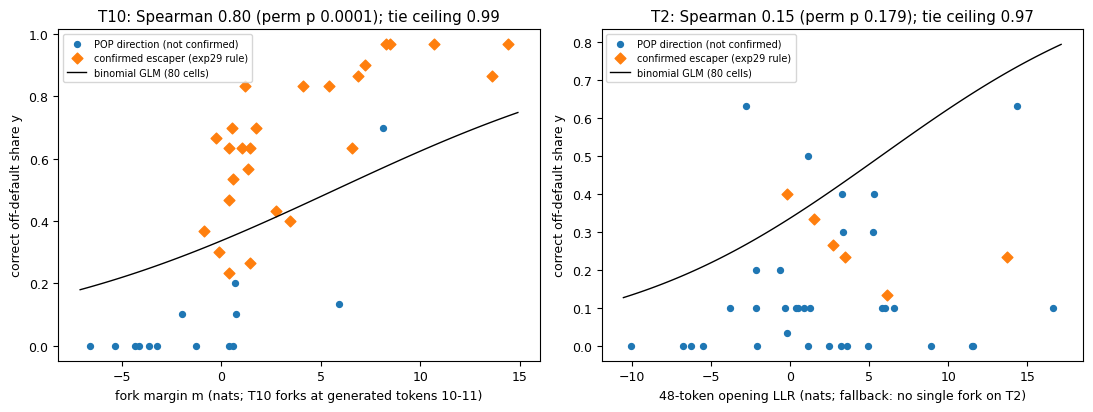

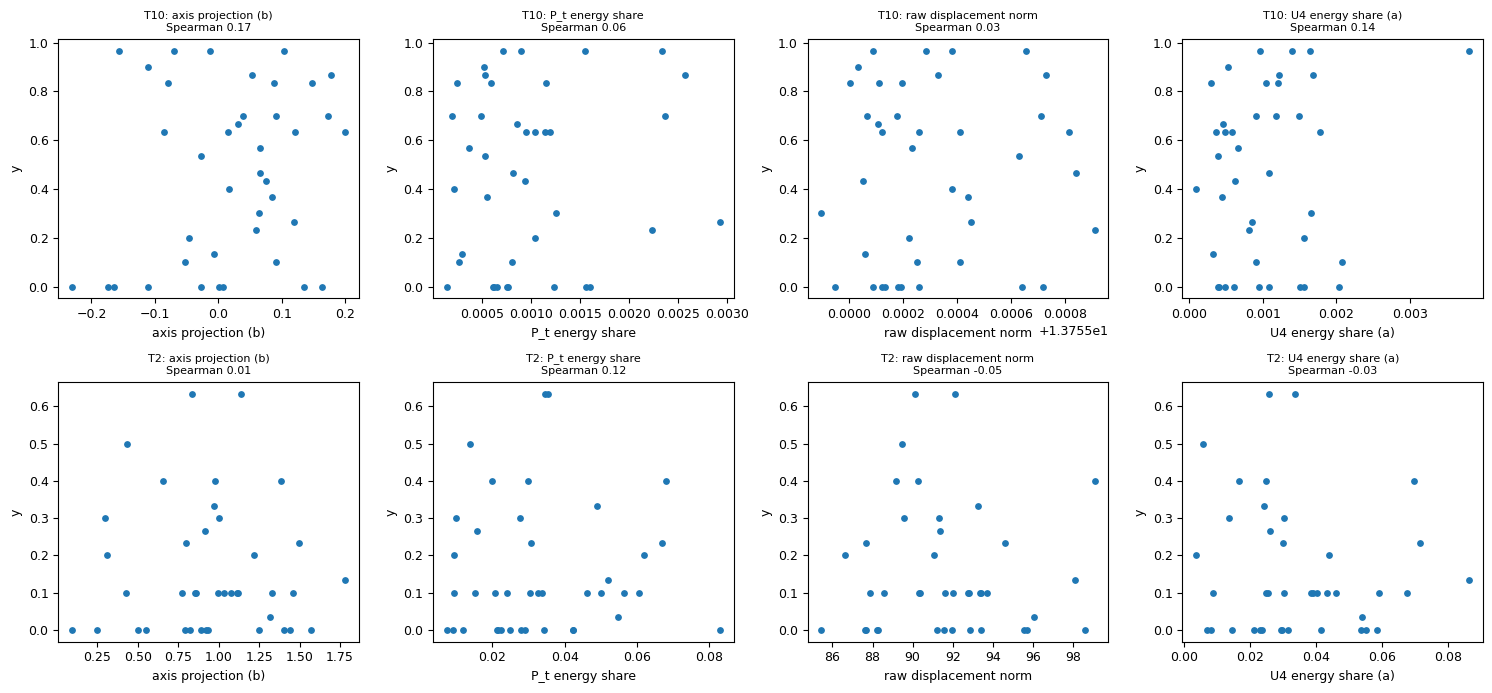

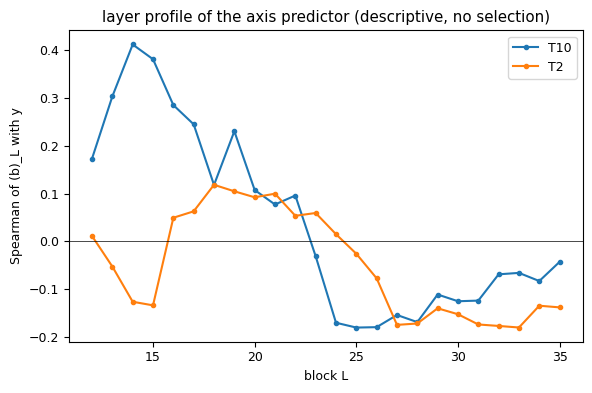

In [14]:
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42})


def save(fig, name: str) -> None:
    fig.tight_layout()
    plt.show()      # notebook: the source writes FIGS / f"{name}.png" and .pdf (dpi 150), then closes the figure


def f2_f3_f4() -> None:
    fa = {"F": res["F"], "cells": res["cells"]}       # notebook: read_json(RESULTS / "f_analysis.json")
    pa = {"P2": res["P2"]}                            # notebook: read_json(RESULTS / "p2_analysis.json")
    cal = fa["F"]["calibration"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, t in zip(axes, ("T10", "T2")):
        rows = fa["cells"][t]
        m = np.array([r["m"] for r in rows])
        y = np.array([r["y"] for r in rows])
        conf = np.array([r["confirmed"] for r in rows])
        ax.scatter(m[conf == 0], y[conf == 0], s=18, label="POP direction (not confirmed)")
        ax.scatter(m[conf == 1], y[conf == 1], s=30, marker="D", label="confirmed escaper (exp29 rule)")
        others = [c for c in cal["cells"] if c["cell"].startswith(t + "|") and "POP_" not in c["cell"]]
        for c in others:
            ax.scatter(c["m"], c["y"], marker="x", color="gray")
            ax.annotate(c["cell"].split("|")[1], (c["m"], c["y"]), fontsize=6, color="gray")
        xs = np.linspace(min(list(m) + [c["m"] for c in others]) - 0.5, max(list(m) + [c["m"] for c in others]) + 0.5,
                         100)
        ax.plot(xs, 1 / (1 + np.exp(-(cal["b0"] + cal["b1"] * xs))), "k-", lw=1,
                label=f"binomial GLM ({cal['n_cells']} cells)")      # notebook: the source says "all cells" (104)
        F = fa["F"][t]
        src = cells.get(f"{t}|TWIN", {}).get("margin_source", "")    # notebook: read_json(c7.c3_path())["cells"]
        ax.set_title(f"{t}: Spearman {F['rho']:.2f} (perm p {F['p_perm']:.3g}); tie ceiling {F['rho_max_ties']:.2f}")
        ax.set_xlabel("fork margin m (nats; T10 forks at generated tokens 10-11)" if "llr" not in src else
                      "48-token opening LLR (nats; fallback: no single fork on T2)")
        ax.set_ylabel("correct off-default share y")
        ax.legend(fontsize=7)
    save(fig, "F2_margin_vs_outcome")
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for row, t in enumerate(("T10", "T2")):
        rows = fa["cells"][t]
        y = np.array([r["y"] for r in rows])
        for ax, (k, nm) in zip(axes[row], (("b", "axis projection (b)"), ("pi_Pt", "P_t energy share"),
                                           ("norm", "raw displacement norm"), ("a_share", "U4 energy share (a)"))):
            x = np.array([r[k] for r in rows])
            ax.scatter(x, y, s=15)
            P = pa["P2"][t]
            rho = P["rho_b"] if k == "b" else P["competitors"][k]["rho"]
            ax.set_title(f"{t}: {nm}\nSpearman {rho:.2f}", fontsize=8)
            ax.set_xlabel(nm)
            ax.set_ylabel("y")
    save(fig, "F3_axis_vs_competitors")
    fig, ax = plt.subplots(figsize=(6, 4))
    for t in ("T10", "T2"):
        prof = pa["P2"][t]["layer_profile"]
        L = sorted(int(k) for k in prof)
        ax.plot(L, [prof[str(l)] for l in L], "-o", ms=3, label=t)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("block L")
    ax.set_ylabel("Spearman of (b)_L with y")
    ax.set_title("layer profile of the axis predictor (descriptive, no selection)")
    ax.legend()
    save(fig, "F4_rho_b_profile")


f2_f3_f4()

## Results: recomputed vs. reported

The table compares the numbers recomputed above with the full run's `results/f_analysis.json` and
`results/p2_analysis.json`, which are stored in the data file's metadata. At the committed resampling counts
(`N_PERM = N_BOOT = 10000`, `N_CAL_SPLITS = 10`) the Spearman, tie-ceiling, Kendall, AUC, permutation-p, CI and Holm
rows come out the same as in the full run. With smaller counts, only the resampled quantities (p values, CIs and
everything built on them) move. The two calibration rows differ by design: this notebook fits 80 cells, the full
run 104.

In [15]:
rep = data["metadata"]["reported_full_run"]
cmp_rows = []
for t in ("T10", "T2"):
    F, Fr, P, Pr = res["F"][t], rep["F"][t], res["P2"][t], rep["P2"][t]
    cmp_rows += [(f"F {t}: Spearman(m, y)", F["rho"], Fr["rho"]),
                 (f"F {t}: permutation p", F["p_perm"], Fr["p_perm"]),
                 (f"F {t}: 95% bootstrap CI, low", F["ci"][0], Fr["ci"][0]),
                 (f"F {t}: 95% bootstrap CI, high", F["ci"][1], Fr["ci"][1]),
                 (f"F {t}: tie ceiling", F["rho_max_ties"], Fr["rho_max_ties"]),
                 (f"F {t}: Kendall tau", F["kendall"], Fr["kendall"]),
                 (f"F {t}: AUC for confirmed escapers", F["auc_confirmed"], Fr["auc_confirmed"]),
                 (f"P2 {t}: Spearman(b, y)", P["rho_b"], Pr["rho_b"]),
                 (f"P2 {t}: permutation p", P["p_perm"], Pr["p_perm"])]
    cmp_rows += [(f"P2 {t}: Spearman of competitor {k}", P["competitors"][k]["rho"], Pr["competitors"][k]["rho"])
                 for k in ("pi_Pt", "norm", "a_share")]
cmp_rows += [("F: pooled within-task rho", res["F"]["pooled"]["rho"], rep["F"]["pooled"]["rho"]),
             ("F: pooled permutation p", res["F"]["pooled"]["p_perm"], rep["F"]["pooled"]["p_perm"]),
             ("P2: pooled within-task rho", res["P2"]["pooled"]["rho"], rep["P2"]["pooled"]["rho"]),
             ("Holm-adjusted p, F", res["verdicts"]["holm"]["F"], rep["verdicts"]["holm"]["F"]),
             ("Holm-adjusted p, P2", res["verdicts"]["holm"]["P2"], rep["verdicts"]["holm"]["P2"]),
             ("calibration: number of cells", res["F"]["calibration"]["n_cells"], rep["F"]["calibration"]["n_cells"]),
             ("calibration: held-out MAE", res["F"]["calibration"]["mae_heldout_mean"],
              rep["F"]["calibration"]["mae_heldout_mean"])]
cmp = pd.DataFrame(cmp_rows, columns=["quantity", "this notebook", "full run (reported)"])
cmp["same"] = np.isclose(cmp["this notebook"].astype(float), cmp["full run (reported)"].astype(float),
                         rtol=1e-9, atol=1e-12)
with pd.option_context("display.max_rows", 100, "display.float_format", "{:.4g}".format):
    display(cmp)
print(f"{int(cmp['same'].sum())}/{len(cmp)} quantities identical to the full run "
      f"(N_PERM={N_PERM}, N_BOOT={N_BOOT}, N_CAL_SPLITS={N_CAL_SPLITS})")
print("verdicts here:    ", {k: res["verdicts"][k] for k in ("F", "P2")})
print("verdicts reported:", {k: rep["verdicts"][k] for k in ("F", "P2")})

,quantity,this notebook,full run (reported),same
0,"F T10: Spearman(m, y)",0.8039,0.8039,True
1,F T10: permutation p,9.999e-05,9.999e-05,True
2,"F T10: 95% bootstrap CI, low",0.617,0.617,True
3,"F T10: 95% bootstrap CI, high",0.9054,0.9054,True
4,F T10: tie ceiling,0.9929,0.9929,True
5,F T10: Kendall tau,0.6387,0.6387,True
6,F T10: AUC for confirmed escapers,0.8104,0.8104,True
7,"P2 T10: Spearman(b, y)",0.1733,0.1733,True
8,P2 T10: permutation p,0.1411,0.1411,True
9,P2 T10: Spearman of competitor pi_Pt,0.05952,0.05952,True


29/31 quantities identical to the full run (N_PERM=10000, N_BOOT=10000, N_CAL_SPLITS=10)
verdicts here:     {'F': 'NOT SUPPORTED (inconclusive)', 'P2': 'DISCONFIRMED'}
verdicts reported: {'F': 'NOT SUPPORTED (inconclusive)', 'P2': 'DISCONFIRMED'}


## How the pushes move the fork tokens, and what the model then writes

The figure below shows the mechanism behind F. Each panel puts the 40 random push directions of a task on the x
axis, sorted by margin m.

* **Top (T10):** the probability the pushed prompt puts on each mapped token at the first fork (token 10), as a mean
  over the 5 templates. The triangles give the probability of `' dfs'` rather than `' find'` at token 11, after
  `' def'`. Under the unpushed twin, `' parent'` (union-find) takes 0.96-0.99 at token 10 in four of the five
  templates (0.73 in W5).
* **Middle (T10):** the algorithms the model actually wrote under the same pushes.
* **Bottom (T2):** the same for T2, sorted by its 48-token LLR margin.

On T10, the pushes that move probability from `' parent'` and `' def find'` to `' #'`, `' from'` or `' def dfs'`
are the ones whose programs become DFS or BFS. On T2 no single early token carries the decision, and the margin does
not order the outcomes. y counts only *correct* programs: on T2 many Bellman-Ford/SPFA programs fail the hidden
tests, so y often sits below the red bar.

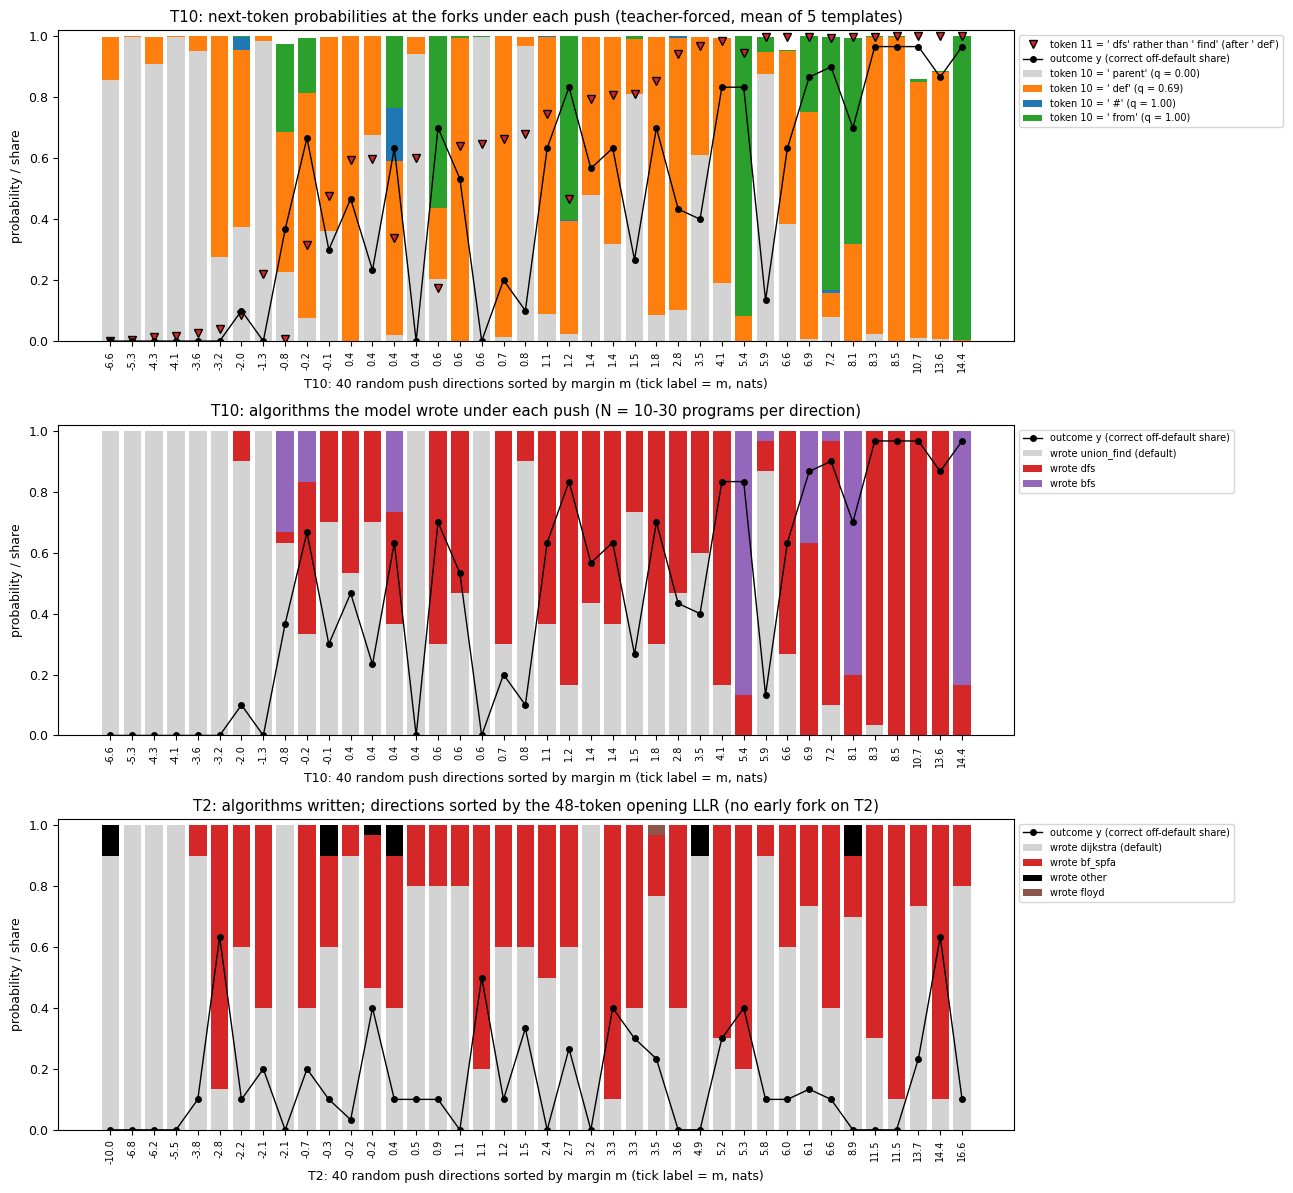

T10: mean y of the 10 lowest-margin pushes 0.11, of the 10 highest-margin pushes 0.80
T2: mean y of the 10 lowest-margin pushes 0.12, of the 10 highest-margin pushes 0.14


In [16]:
tm10, tm11 = fk["token_maps"]["10"], fk["token_maps"]["11"]
dfs_id = next(k for k, v in tm11.items() if v["tok"] == " dfs")
tok_color = {" parent": "lightgray", " def": "tab:orange", " #": "tab:blue", " from": "tab:green"}
lab_color = {"dfs": "tab:red", "bfs": "tab:purple", "bf_spfa": "tab:red", "floyd": "tab:brown", "other": "black"}
by_task = {t: sorted((e for e in examples if e["metadata_task"] == t),
                     key=lambda e: e["metadata_committed_predictors"]["m"]) for t in ("T10", "T2")}


def label_bars(ax, rows, task):
    """Stacked shares of the algorithms written under each push (default algorithm in light gray)."""
    tot = defaultdict(int)
    for e in rows:
        for l, c in e["metadata_outcome"]["labels"].items():
            tot[l] += c
    order = [DEFAULTS[task]] + sorted((l for l in tot if l != DEFAULTS[task]), key=lambda l: -tot[l])
    bottom = np.zeros(len(rows))
    for l in order:
        share = np.array([e["metadata_outcome"]["labels"].get(l, 0) / e["metadata_outcome"]["n"] for e in rows])
        ax.bar(np.arange(len(rows)), share, bottom=bottom, width=0.8,
               color="lightgray" if l == DEFAULTS[task] else lab_color.get(l, "tab:olive"),
               label=f"wrote {l} (default)" if l == DEFAULTS[task] else f"wrote {l}")
        bottom += share


fig, axes = plt.subplots(3, 1, figsize=(13, 12))
rows10 = by_task["T10"]
bottom = np.zeros(len(rows10))
for k, v in sorted(tm10.items(), key=lambda kv: kv[1]["q"]):
    if not v["mapped"]:
        continue
    pk = np.array([np.mean([e["metadata_fork_token_probs"][w]["10"][k] for w in TEMPLATES]) for e in rows10])
    axes[0].bar(np.arange(len(rows10)), pk, bottom=bottom, width=0.8, color=tok_color.get(v["tok"]),
                label=f"token 10 = {v['tok']!r} (q = {v['q']:.2f})")
    bottom += pk
p_dfs = [np.mean([e["metadata_fork_token_probs"][w]["11"][dfs_id] / sum(e["metadata_fork_token_probs"][w]["11"].values())
                  for w in TEMPLATES]) for e in rows10]
axes[0].plot(np.arange(len(rows10)), p_dfs, "v", color="tab:red", mec="k", ms=6,
             label="token 11 = ' dfs' rather than ' find' (after ' def')")
axes[0].set_title("T10: next-token probabilities at the forks under each push (teacher-forced, mean of 5 templates)")
label_bars(axes[1], rows10, "T10")
axes[1].set_title("T10: algorithms the model wrote under each push (N = 10-30 programs per direction)")
label_bars(axes[2], by_task["T2"], "T2")
axes[2].set_title("T2: algorithms written; directions sorted by the 48-token opening LLR (no early fork on T2)")
for ax, t in zip(axes, ("T10", "T10", "T2")):
    rows_t = by_task[t]
    ax.plot(np.arange(len(rows_t)), [e["metadata_outcome"]["y"] for e in rows_t], "k.-", lw=1, ms=8,
            label="outcome y (correct off-default share)")
    ax.set_xticks(np.arange(len(rows_t)), [f"{e['metadata_committed_predictors']['m']:.1f}" for e in rows_t],
                  rotation=90, fontsize=7)
    ax.set_xlabel(f"{t}: 40 random push directions sorted by margin m (tick label = m, nats)")
    ax.set_ylabel("probability / share")
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
plt.show()

for t in ("T10", "T2"):
    rows_t = by_task[t]
    lo, hi = rows_t[:10], rows_t[-10:]
    print(f"{t}: mean y of the 10 lowest-margin pushes {np.mean([e['metadata_outcome']['y'] for e in lo]):.2f}, "
          f"of the 10 highest-margin pushes {np.mean([e['metadata_outcome']['y'] for e in hi]):.2f}")

## What the rest of `method.py` found (GPU stages, not re-run here)

These are the numbers of the full run, from the artifact's `README.md` and `method_out.json`:

* **Forks** (stage `forks`; 4,560 prefix-resampled continuations, permutation-null change points). T10 decides at
  generated tokens 10-11, and H(label | token) is 0 bits at token 11. T2 has no early fork: pushed paths stay
  undecided through token 60, and the only change point (token 92) lies off the default opening. On T03 (k-th
  smallest) the prompt fixes the algorithm before the first generated token.
* **T03 prospective confirmation.** 24 fresh directions, with predictions hash-committed before generation. The
  margin gives Spearman 0.60 (one-sided p 0.0014); the axis projection gives 0.22 (p 0.15).
* **Necessity (mediator clamp).** Removing the axis component of the push leaves 105 escapes, against 104 without
  the clamp and 106 with a random-direction clamp. The axis does not carry the random pushes.
* **Sufficiency (targeted push along the axis).** No task escapes at the committed doses s ≤ 1. At s = 4, T10
  writes a correct DFS on 29/30 slots, against 0/30 for a matched random direction. T2 shows no escape even at s = 8.
* **T1 grid path: in-manifold top-five push.** Pushes toward the survivor centroids of the algorithm manifold
  (Isomap/MDS/PCA in real activation coordinates) give 0/300 programs outside the top five, all BFS. A prompt that
  bans the top five still gets 48/50 BFS or DFS programs (exp30).
* **Forced token (exploratory, post hoc).** Writing `def dfs` instead of `def find` at tokens 10-11, under the
  unchanged twin prompt, gives 30/30 correct DFS programs. A comment token at token 10 leaves the model on
  union-find (30/30).

**Bottom line.** On T10, one early token decides the algorithm, and the fork margin predicts which random pushes
change it (F holds on T10: rho 0.80). F fails on T2, where the decision comes late, so the committed two-task F is
NOT SUPPORTED (inconclusive). The default-to-runner-up axis neither predicts nor mediates the pushes (P2
DISCONFIRMED), although a strong push along it is a sufficient control direction on T10.

**Full pipeline.** Clone the repository and `cd` into the experiment folder. Then run
`uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml` and
`.venv/bin/python method.py --stages all`. This needs one 24 GB GPU, `Qwen/Qwen3-8B` at revision
`b968826d9c46dd6066d109eabc6255188de91218`, and about 3 hours of wall-clock (1.7 GPU-hours).